# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from matplotlib.colors import ListedColormap, Normalize
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box
import numpy as np
import pandas as pd
import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [109]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr")

In [110]:
def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "transcript_type",
    shapes_key: str = "cell_boundaries",
    colormap: str = "30colors",
    boundary_linewidth: float = 0.5,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot cell boundary polygons and transcript points, colored by a categorical variable
    or a numeric variable, scaling geometries by an affine matrix from get_transformation.

    Parameters
    ----------
    sdata
        A SpatialData object containing:
          - sdata[shapes_key]  including a 'geometry' column of shapely Polygons
          - sdata['transcripts'] including `gene_key` and `color_key`
    gene_key: str
        Column in transcripts to filter by gene_list.
    gene_list: Optional[List[str]]
        List of genes to keep. If None, all transcripts are used.
    color_key: str
        Column in transcripts used for coloring points. Can be categorical or numeric.
    shapes_key: str
        Key in sdata for your polygon boundaries layer.
    colormap: str
        Name of a Matplotlib colormap or troutpy palette name.
    boundary_linewidth: float
        Line width of cell boundary outlines.
    scatter_size: float
        Marker size for transcript points.
    alpha: float
        Transparency for transcript points.
    use_roi: bool
        If True, restrict both polygons and points to the bounding box given by `roi`.
    roi: Tuple[float, float, float, float]
        (xmin, xmax, ymin, ymax) bounds to clip to when `use_roi=True`.
    figsize: Tuple[float, float]
        Width and height of the figure.
    title: str
        Title string placed above the plot.

    Returns
    -------
    fig, ax
        The Matplotlib figure and axes objects.
    """
    # 1) Filter transcripts by gene_list
    trans_ad = sdata["transcripts"].compute()
    if gene_list is not None:
        trans_ad = trans_ad[trans_ad[gene_key].isin(gene_list)]

    # annotate transcript types
    trans_ad["segstatus"] = trans_ad["overlaps_cell"].astype(str) + "_" + trans_ad["extracellular"].astype(str)
    stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}
    trans_ad["transcript_type"] = trans_ad["segstatus"].map(stat2lab)

    # 2) Prepare color values based on type (categorical or numeric)
    trans_df = trans_ad.copy()
    if pd.api.types.is_numeric_dtype(trans_df[color_key]):
        is_numeric = True
        color_values = trans_df[color_key].astype(float)
        cmap = plt.get_cmap(colormap)
        norm = Normalize(vmin=color_values.min(), vmax=color_values.max())
    else:
        is_numeric = False
        cats = trans_df[color_key].astype("category")
        color_values = cats.cat.codes.values
        n_cats = len(cats.cat.categories)
        try:
            import troutpy
            pal = troutpy.pl.get_palette(colormap, n_cats)
            cmap = ListedColormap(pal)
        except Exception:
            cmap = plt.get_cmap(colormap, n_cats)

    # 3) Obtain affine transformation and apply to geometries and points
    cb = sdata[shapes_key]
    df = cb.copy()
    trans = get_transformation(cb)
    
    if hasattr(trans, "matrix") and trans.matrix is not None:
        try:
            matrix = trans.matrix  # expected 3x3 or 2x3 affine
            a, b, xoff = matrix[0]
            d, e, yoff = matrix[1]
            params = [a, b, d, e, xoff, yoff]
            df["geometry"] = df["geometry"].apply(lambda geom: affine_transform(geom, params))
        except Exception as e:
            print(f"Transformation could not be applied: {e}")
    else:
        print("No transformation matrix found. Proceeding without transformation.")

    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs=None)

    # 4) Optionally clip to ROI
    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        color_values = color_values[mask]  # mask color values too

    # 5) Plot
    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth)
    scatter = ax.scatter(
        trans_df["x"],
        trans_df["y"],
        c=color_values,
        cmap=cmap,
        s=scatter_size,
        edgecolor="none",
        alpha=alpha,
        norm=norm if is_numeric else None,
    )

    # 6) Legend or colorbar
    if is_numeric:
        cbar = fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
    else:
        for idx, cat in enumerate(cats.cat.categories):
            ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
        ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


In [111]:
import numpy as np
import scanpy as sc

def compute_projection_score(sdata):
    """
    Compute a segmentation score for each cell based on the expression of genes weighted by their intracellular proportion (1 - extracellular proportion).

    Parameters
    ----------
    sdata : dict
        A spatialdata object with keys 'table' and 'xrna_metadata'.
        - sdata['table'] is an AnnData object containing expression data in layers['raw']
          and cell metadata in .obs.
        - sdata['xrna_metadata'].var is a DataFrame with gene names as the index and
          an 'extracellular proportion' column.

    Returns
    -------
    sdata : dict
        The same sdata object with a new column 'segmentation_score' in sdata['table'].obs.
    """
    # Retrieve the AnnData object with cells in .obs and genes in .var
    adata = sdata["table"]

    # Retrieve raw expression data; assume shape (n_cells, n_genes)
    raw_expr = adata.layers["raw"]

    # If raw_expr is a sparse matrix, convert to a dense array
    if hasattr(raw_expr, "toarray"):
        raw_expr = raw_expr.toarray()

    # Get gene names from the AnnData object
    genes = adata.var_names

    # Retrieve gene metadata containing the extracellular proportions
    gene_meta = sdata["xrna_metadata"].var

    # Identify the genes common to both the expression data and the metadata
    common_genes = gene_meta.index.intersection(genes)
    if len(common_genes) == 0:
        raise ValueError("No common genes found between adata and gene metadata.")

    # Subset the expression matrix to only those common genes
    # Here we assume adata.var_names preserves order; get indices corresponding to common genes.
    common_idx = [i for i, gene in enumerate(genes) if gene in common_genes]
    raw_expr = raw_expr[:, common_idx]

    # Reorder gene_meta so that it matches the ordering in the expression data.
    # This assumes that the order of genes in adata.var_names is the desired order.
    ordered_genes = [gene for gene in genes if gene in common_genes]
    gene_weights = gene_meta.loc[ordered_genes, "extracellular_proportion"]

    # Convert extracellular proportion to intracellular weight (1 - extracellular proportion)
    extracellular_weights =  gene_weights.values  # numpy array

    # Compute the numerator and denominator for the weighted average per cell.
    # Numerator: dot product of cell expression with intracellular weights.
    # Denominator: total expression (for the common genes) per cell.
    numerator = raw_expr.dot(extracellular_weights)
    denominator = raw_expr.sum(axis=1)

    # Avoid division by zero (if a cell has zero expression for these genes)
    score = np.divide(numerator, denominator, out=np.full_like(numerator, np.nan), where=denominator != 0)

    # Store the score in the AnnData object under obs
    adata.obs["projection_score"] = score


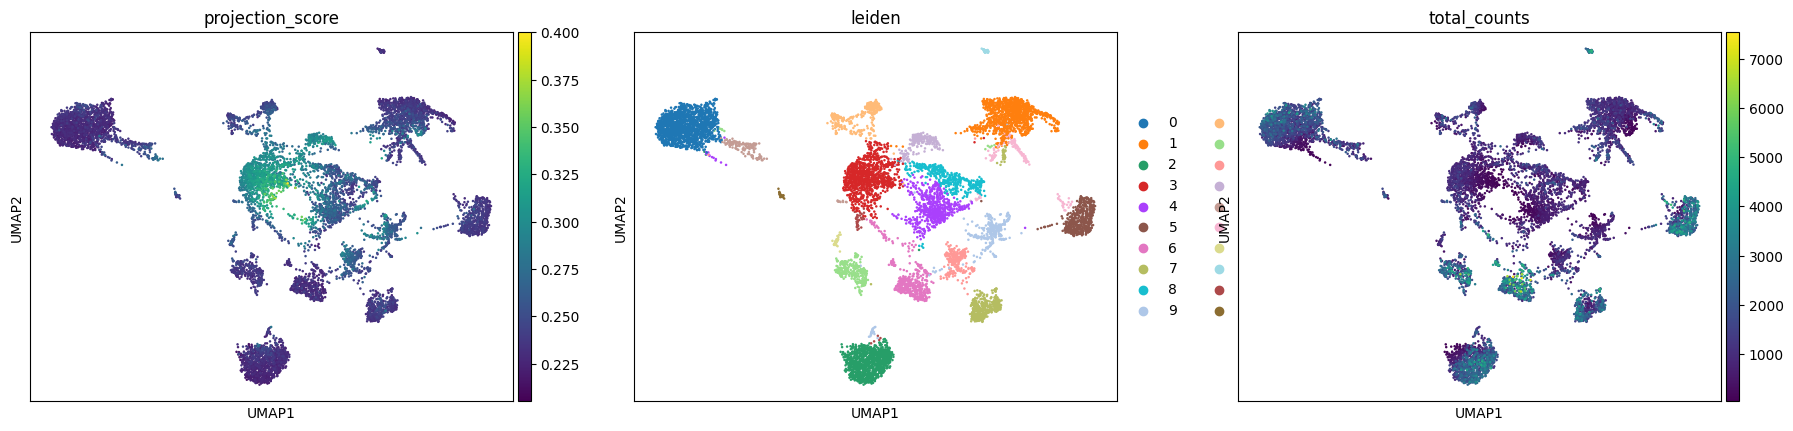

In [112]:
compute_projection_score(sdata)

sc.pl.umap(sdata["table"], color=["projection_score", "leiden", "total_counts"], vmax="p99.997")

In [113]:
adata=sdata['table']

In [117]:
sc.pp.filter_genes(adata,min_counts=100)

In [118]:
adata

AnnData object with n_obs × n_vars = 9185 × 3393
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'leiden', 'projection_score'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_id', 'n_cells', 'n_counts'
    uns: 'dendrogram_leiden', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'connectivities', 'distances'

Number of pure genes: 376


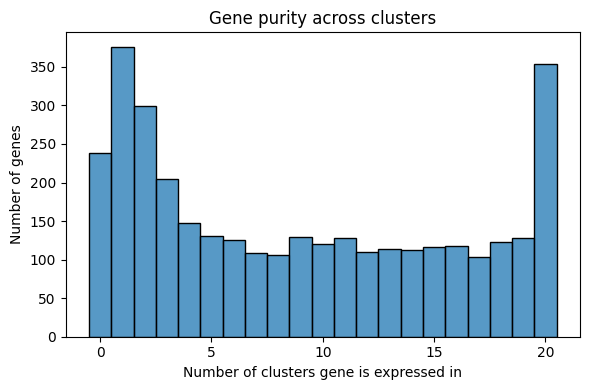

In [119]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

def compute_gene_cluster_purity(adata, cluster_key="leiden", min_expr_frac=0.05):
    """
    Computes cluster purity of genes, defined as being expressed in only one cluster.

    Parameters
    ----------
    adata : AnnData
        Annotated data matrix with gene expression.
    cluster_key : str
        Column in adata.obs containing cluster labels.
    min_expr_frac : float
        Minimum fraction of cells in a cluster in which a gene must be expressed
        (nonzero) to be considered expressed in that cluster.

    Returns
    -------
    gene_purity_df : pd.DataFrame
        DataFrame with genes, number of clusters expressed in, and purity label.
    pure_genes : list
        List of genes expressed in only one cluster.
    """
    clusters = adata.obs[cluster_key].astype(str).unique()
    clusters.sort()
    gene_names = adata.var_names

    expr = adata.X
    if not isinstance(expr, np.ndarray):
        expr = expr.toarray()

    # Binary matrix: cell x gene (1 if expressed)
    expr_bin = expr > 0

    # Create a gene x cluster expression fraction matrix
    gene_expr_in_clusters = pd.DataFrame(0.0, index=gene_names, columns=clusters)

    for cluster in clusters:
        cell_mask = adata.obs[cluster_key] == cluster
        cluster_expr_bin = expr_bin[cell_mask.values, :]
        frac_expr = cluster_expr_bin.sum(axis=0) / cell_mask.sum()
        gene_expr_in_clusters.loc[:, cluster] = frac_expr

    # Determine number of clusters where each gene is expressed
    is_expressed = gene_expr_in_clusters >= min_expr_frac
    num_clusters_expressed = is_expressed.sum(axis=1)

    # Genes with purity = 1 are expressed in only one cluster
    purity_df = pd.DataFrame({
        "n_clusters_expressed": num_clusters_expressed,
        "pure": num_clusters_expressed == 1
    })

    return purity_df, purity_df[purity_df["pure"]].index.tolist(), gene_expr_in_clusters

# ---- Run the pipeline ----
purity_df, pure_genes, gene_expr_in_clusters = compute_gene_cluster_purity(adata,min_expr_frac=0.15)

print(f"Number of pure genes: {len(pure_genes)}")

# ---- Visualization ----

# Histogram of number of clusters each gene is expressed in
plt.figure(figsize=(6, 4))
sns.histplot(purity_df["n_clusters_expressed"], bins=range(1, purity_df["n_clusters_expressed"].max() + 2), discrete=True)
plt.xlabel("Number of clusters gene is expressed in")
plt.ylabel("Number of genes")
plt.title("Gene purity across clusters")
plt.tight_layout()
plt.show()

In [120]:
len(pure_genes)

376

## Latent factor analysis

In [121]:
adata = sdata["table"]
adata=adata[:,pure_genes]

In [122]:
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")
hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

100%|██████████| 376/376 [00:00<00:00, 924.45it/s]


Computing pair-wise local correlation on 345 features...


100%|██████████| 59340/59340 [00:07<00:00, 7535.23it/s]


In [123]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=5, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

Computing scores for 21 modules...


100%|██████████| 21/21 [00:01<00:00, 15.84it/s]


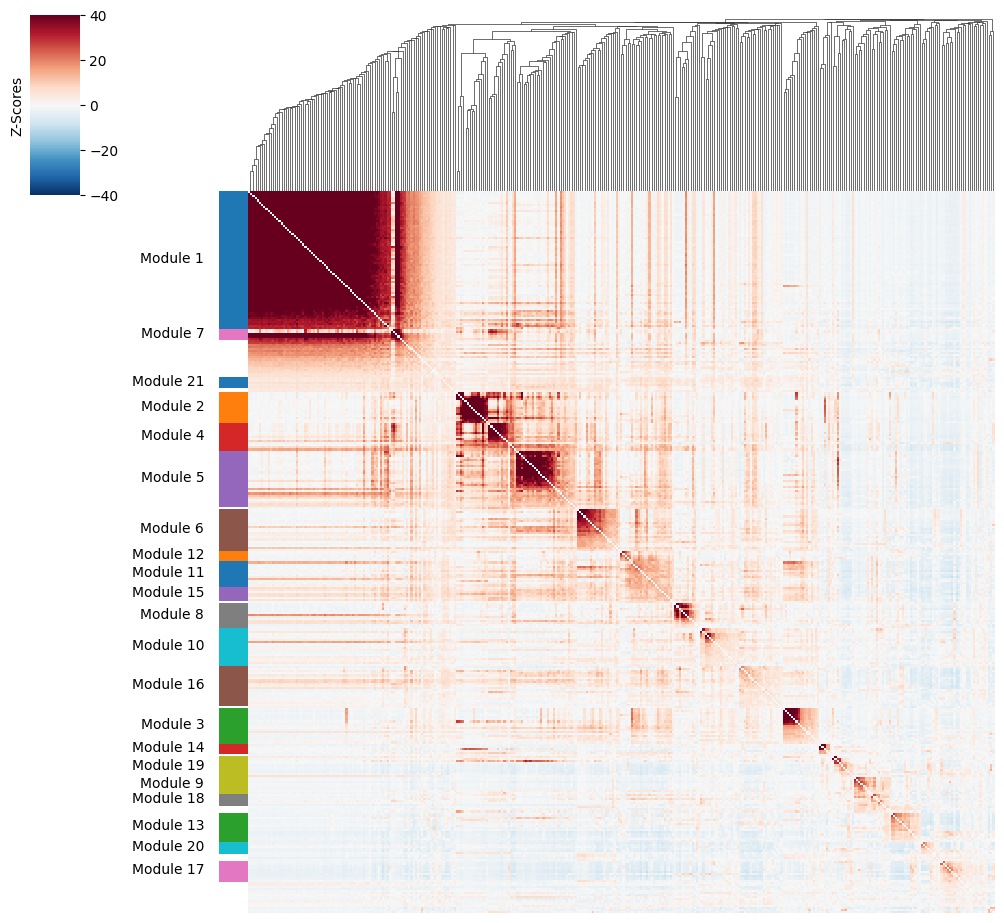

In [124]:
hs.plot_local_correlations(vmax=40, vmin=-40)

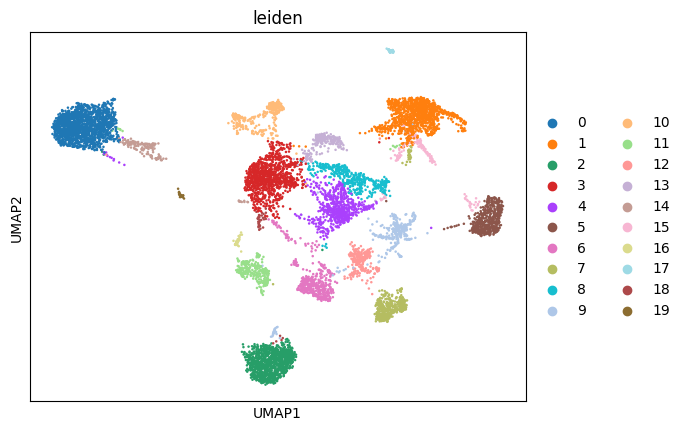

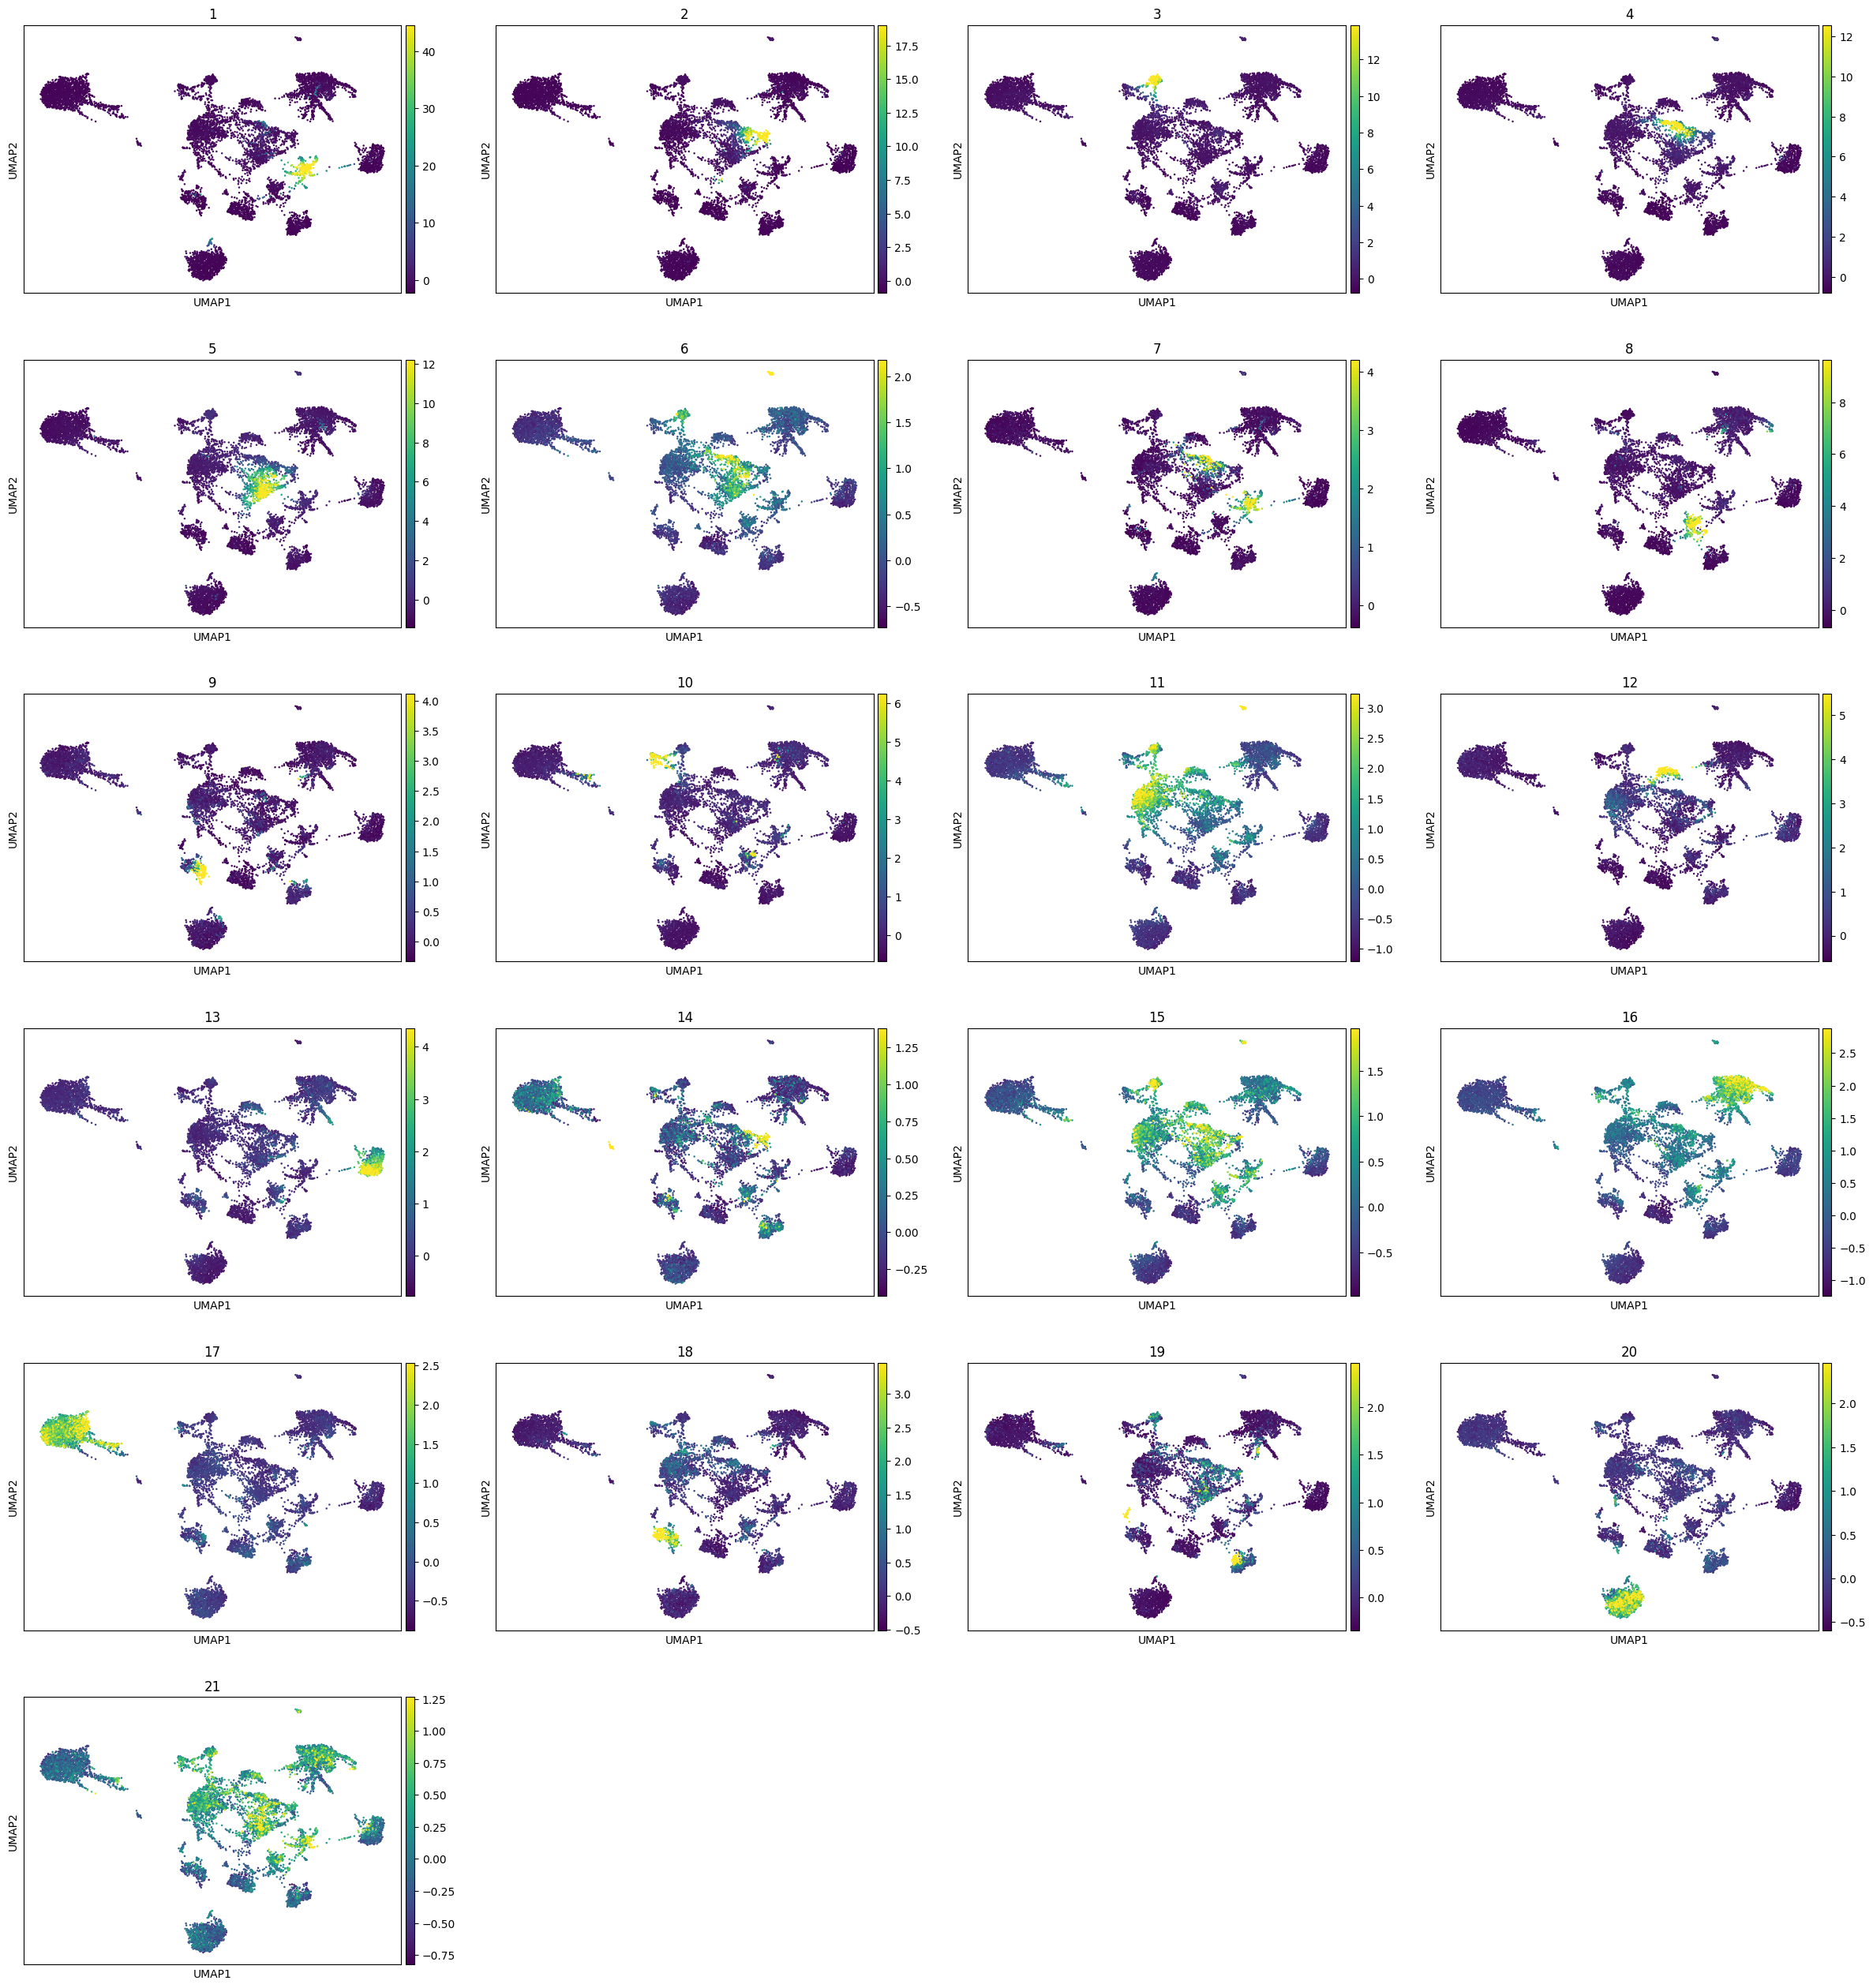

In [125]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [126]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [127]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [145]:
def compute_cluster_exrna_scores(sdata, cluster_key="leiden", min_cells=10):
    adata = sdata["table"]
    gene_meta = sdata["xrna_metadata"].var

    expr = adata.X
    if not isinstance(expr, np.ndarray):
        expr = expr.toarray()

    clusters = adata.obs[cluster_key]
    gene_names = adata.var_names
    cluster_ids = clusters.unique()

    extracellular_proportion = gene_meta["extracellular_proportion"]
    common_genes = gene_names.intersection(extracellular_proportion.index)

    gene_idx = [i for i, g in enumerate(gene_names) if g in common_genes]
    gene_names = gene_names[gene_idx]
    expr = expr[:, gene_idx]
    extracellular_proportion = extracellular_proportion[gene_names]

    total_expr_per_gene = expr.sum(axis=0)
    cluster_expr = pd.DataFrame(index=gene_names, columns=cluster_ids)
    cluster_potential = {}

    for cluster in cluster_ids:
        cell_mask = clusters == cluster
        if cell_mask.sum() < min_cells:
            continue
        cluster_data = expr[cell_mask.values, :]
        cluster_sum = cluster_data.sum(axis=0)

        # Store expression
        cluster_expr[cluster] = cluster_sum

        # Compute exRNA potential of the cluster
        weighted_avg = np.average(extracellular_proportion.values, weights=cluster_sum)
        cluster_potential[cluster] = weighted_avg

    # Now compute gene-cluster exRNA contribution score
    exrna_scores = pd.DataFrame(index=gene_names, columns=cluster_ids)

    for cluster in cluster_ids:
        if cluster not in cluster_potential:
            continue
        cluster_sum = cluster_expr[cluster].values
        fractional_expr = cluster_sum / total_expr_per_gene
        score = cluster_potential[cluster] * fractional_expr * extracellular_proportion.values
        exrna_scores.loc[:, cluster] = score

    exrna_scores = exrna_scores.fillna(0)

    return exrna_scores, cluster_potential


In [146]:
# Run model
exrna_scores, cluster_potential = compute_cluster_exrna_scores(sdata)

# Plot per-gene contribution from each cluster
def plot_top_contributors(gene, exrna_scores, top_k=5):
    contrib = exrna_scores.loc[gene].sort_values(ascending=False).head(top_k)
    plt.figure(figsize=(6, 3))
    sns.barplot(x=contrib.index, y=contrib.values)
    plt.title(f"Top {top_k} cluster contributions for {gene}")
    plt.ylabel("Adjusted exRNA contribution")
    plt.xlabel("Cluster")
    plt.ylim(0, None)
    plt.tight_layout()
    plt.show()

# Plot cluster-level exRNA potential
def plot_cluster_exrna_potential(cluster_potential):
    sorted_potentials = pd.Series(cluster_potential).sort_values(ascending=False)
    plt.figure(figsize=(6, 3))
    sns.barplot(x=sorted_potentials.index, y=sorted_potentials.values)
    plt.title("Cluster-level exRNA potential")
    plt.ylabel("Avg extracellular enrichment of expressed genes")
    plt.xlabel("Cluster")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


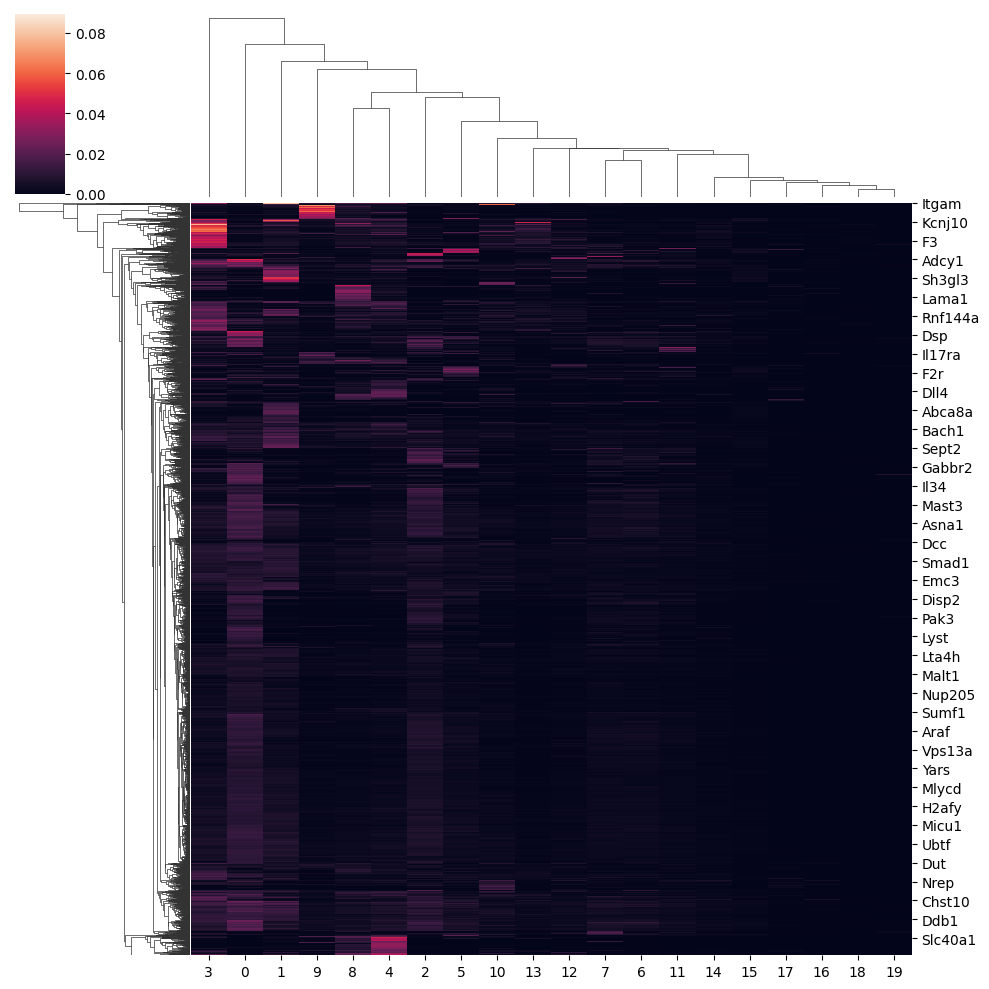

In [150]:
sns.clustermap(exrna_scores)

In [148]:
plot_top_contributors(gene, exrna_scores, top_k=5)

NameError: name 'gene' is not defined

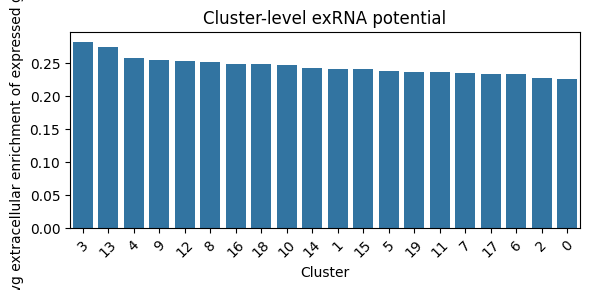

In [147]:
plot_cluster_exrna_potential(cluster_potential)

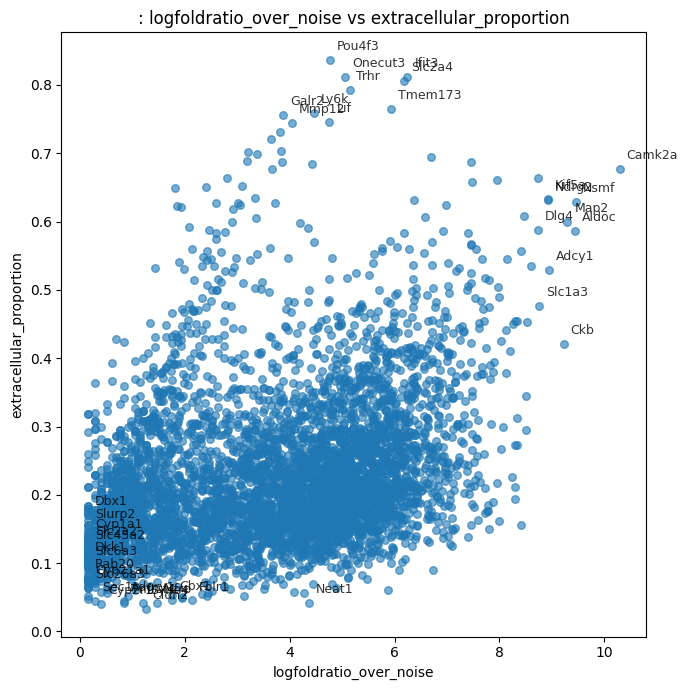

In [128]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

1.0


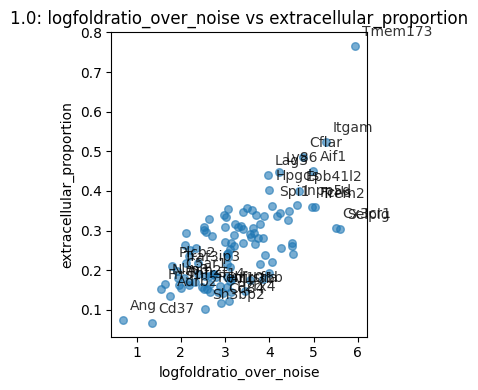

2.0


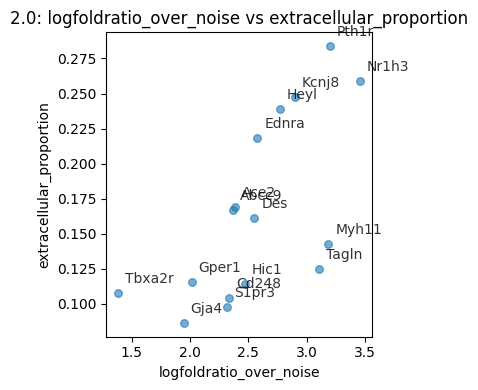

3.0


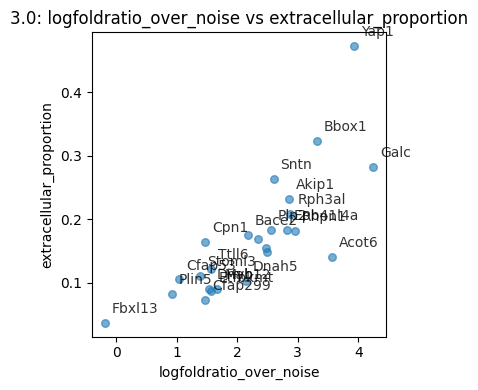

4.0


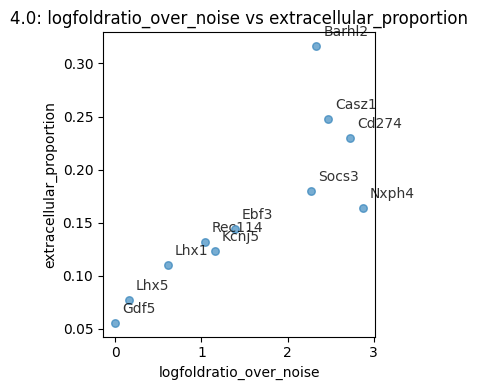

5.0


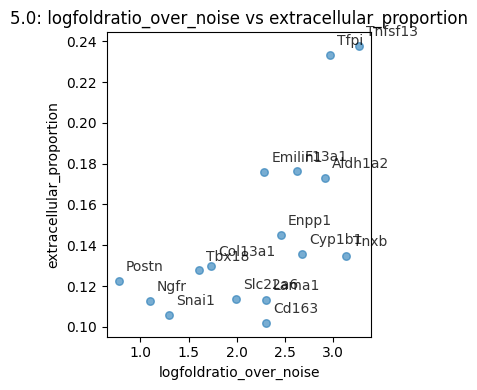

6.0


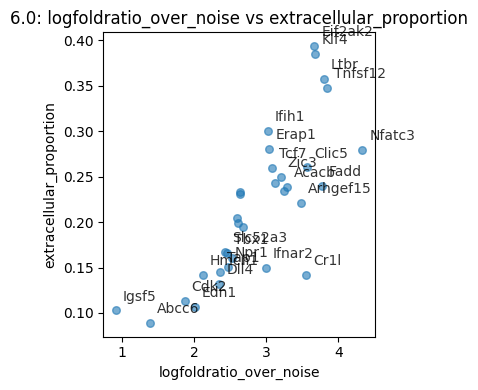

7.0


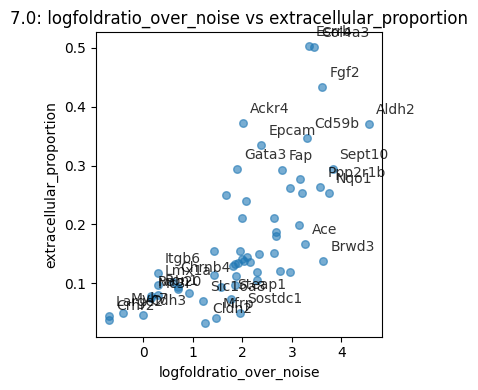

8.0


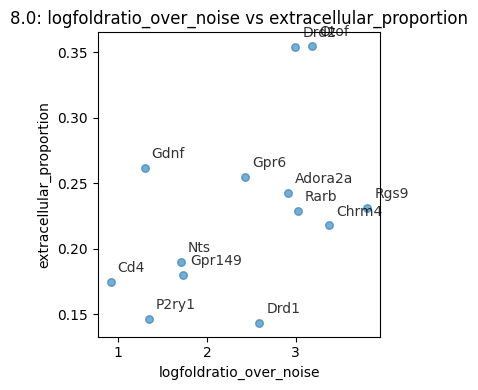

9.0


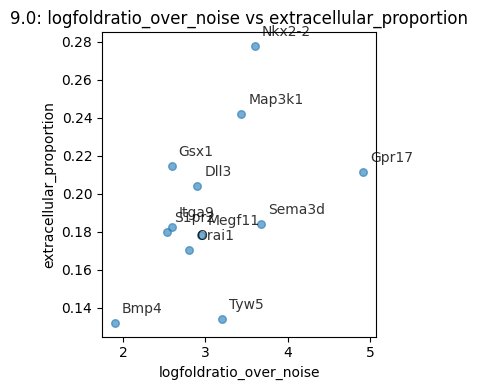

10.0


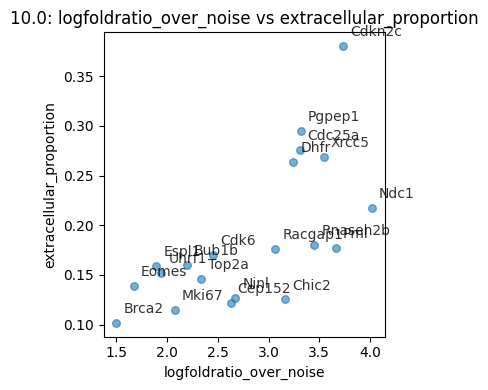

11.0


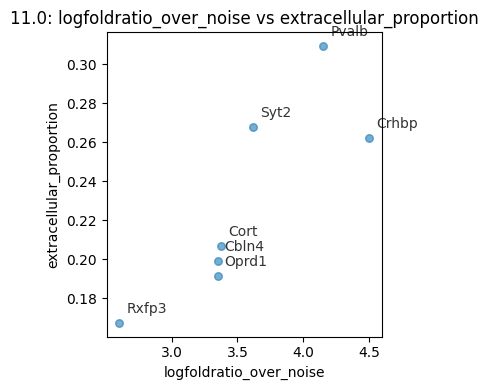

12.0


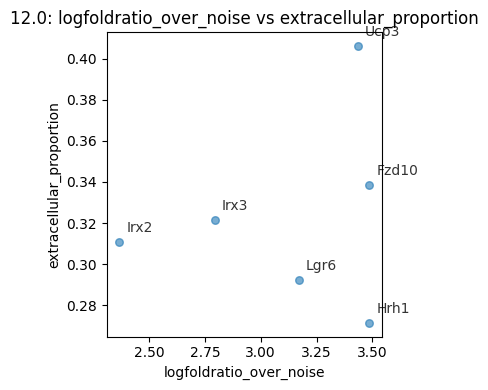

13.0


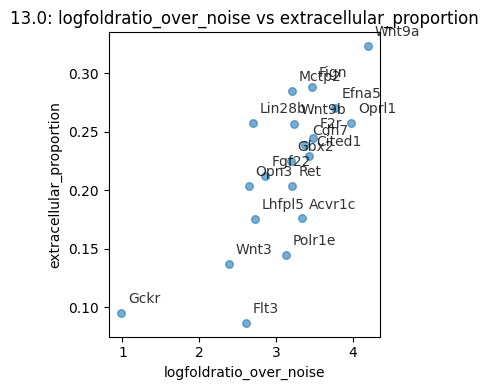

14.0


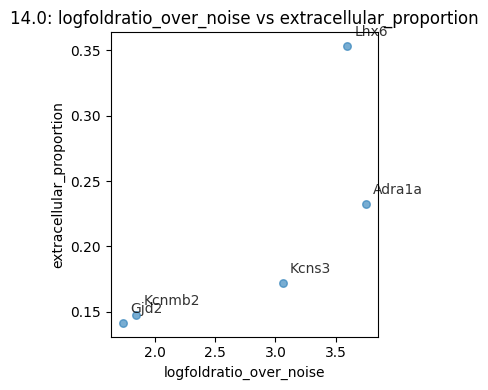

15.0


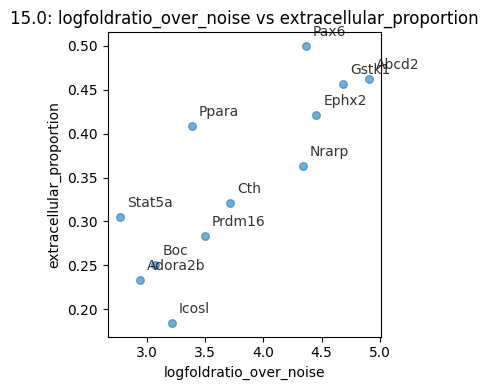

16.0


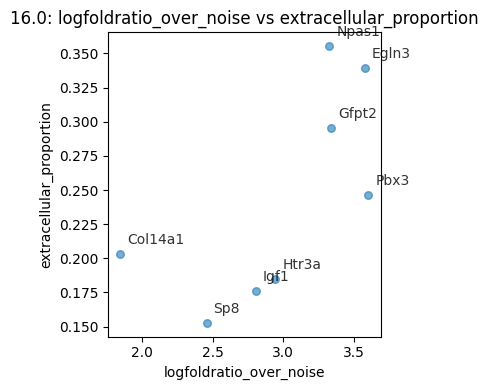

17.0


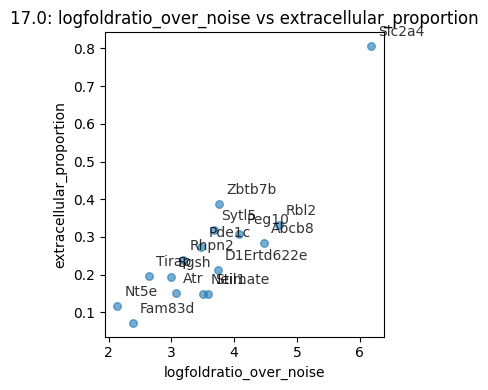

18.0


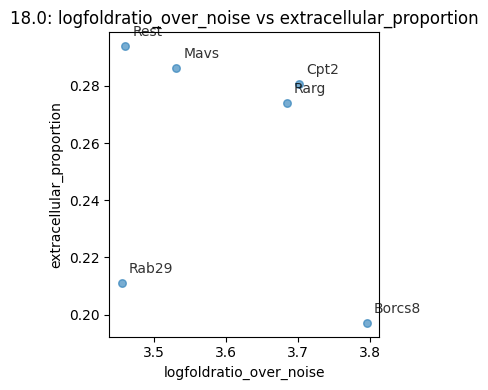

19.0


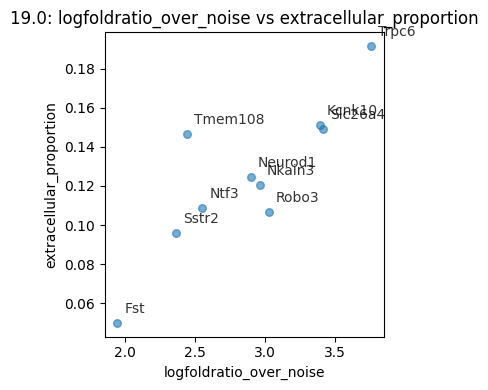

20.0


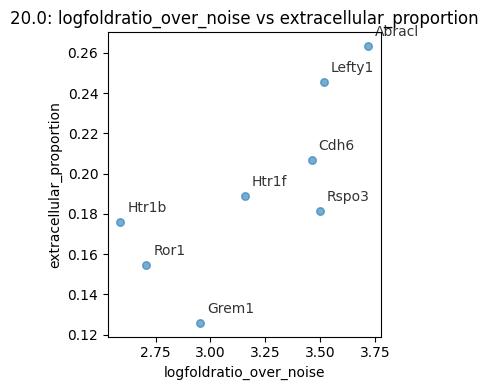

21.0


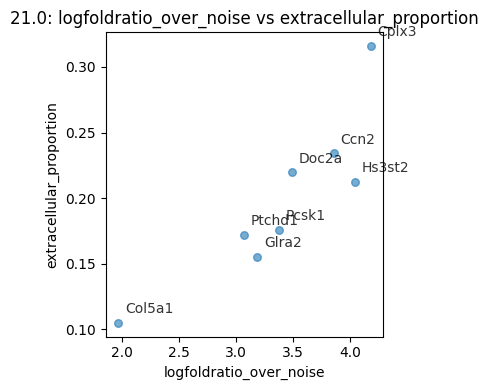

22.0


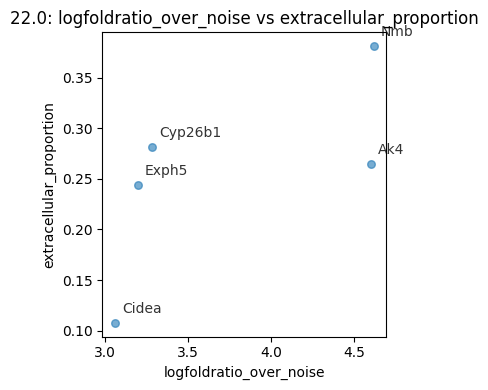

In [104]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=10,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 10, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

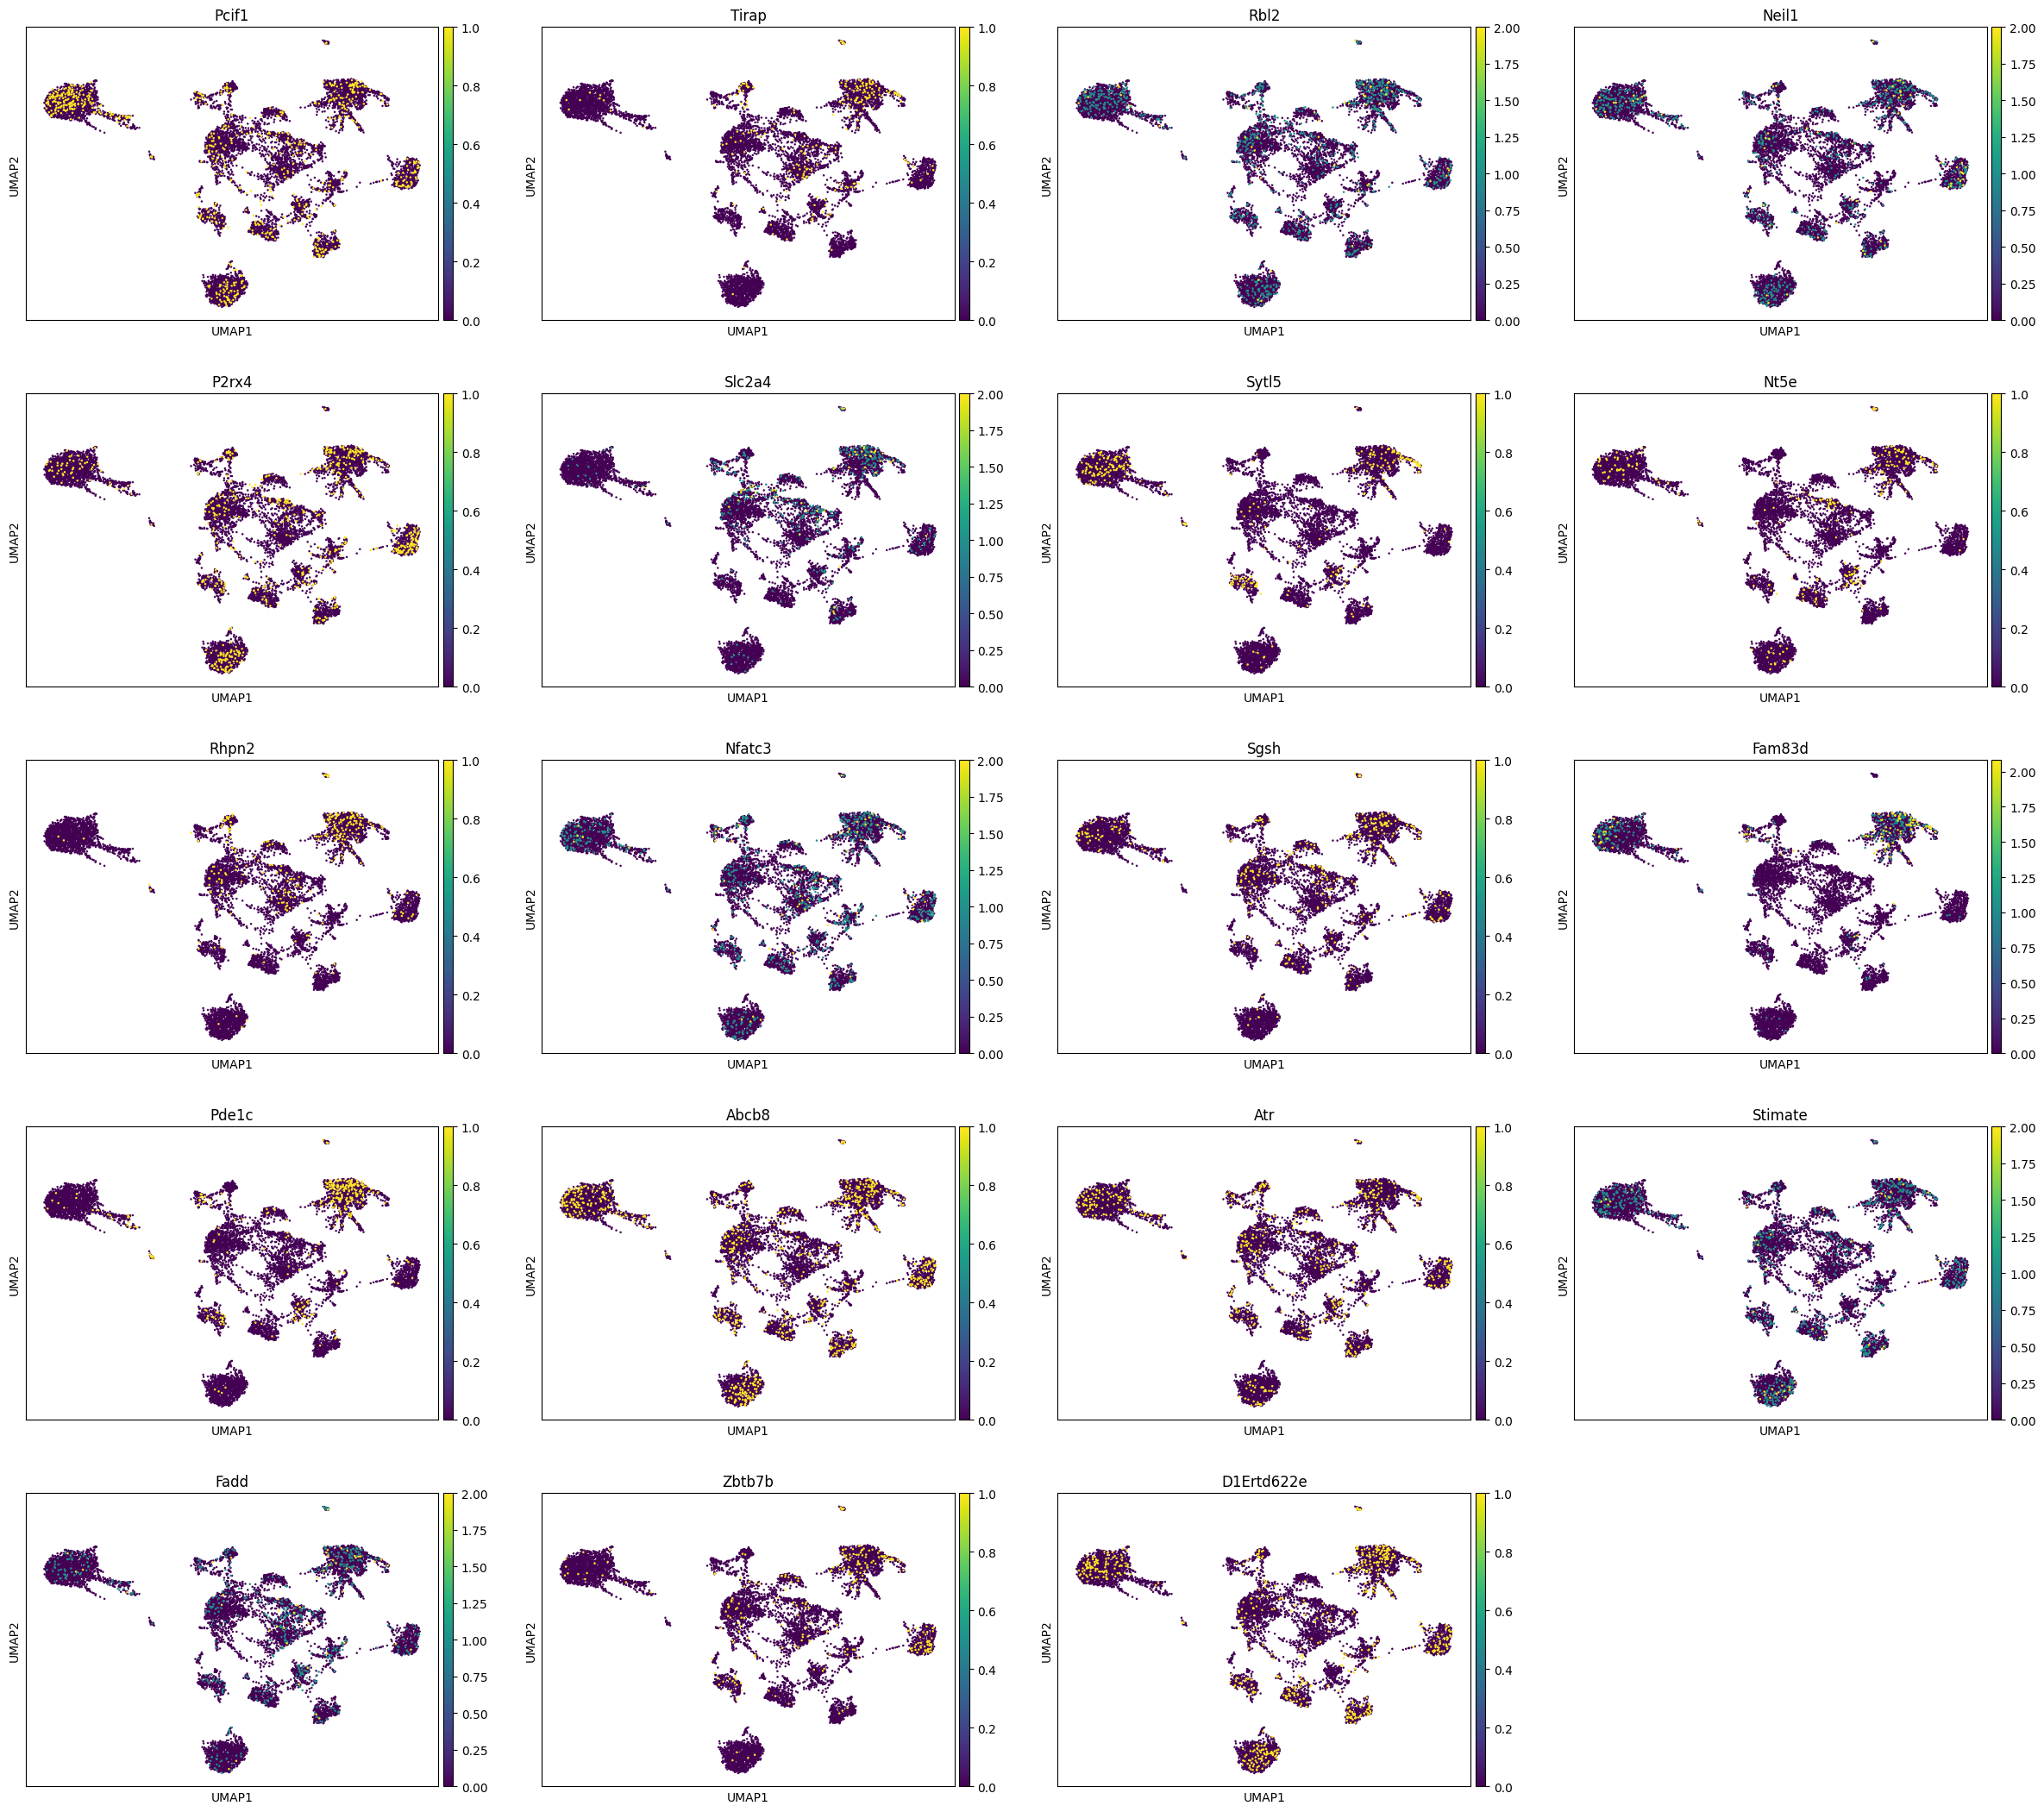

Index(['Pcif1', 'Tirap', 'Rbl2', 'Neil1', 'P2rx4', 'Slc2a4', 'Sytl5', 'Nt5e',
       'Rhpn2', 'Nfatc3', 'Sgsh', 'Fam83d', 'Pde1c', 'Abcb8', 'Atr', 'Stimate',
       'Fadd', 'Zbtb7b', 'D1Ertd622e'],
      dtype='object')


In [140]:
import pandas as pd
mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 16.0].index
sc.pl.umap(adata, color=genes, vmax="p99.5")
print(genes)

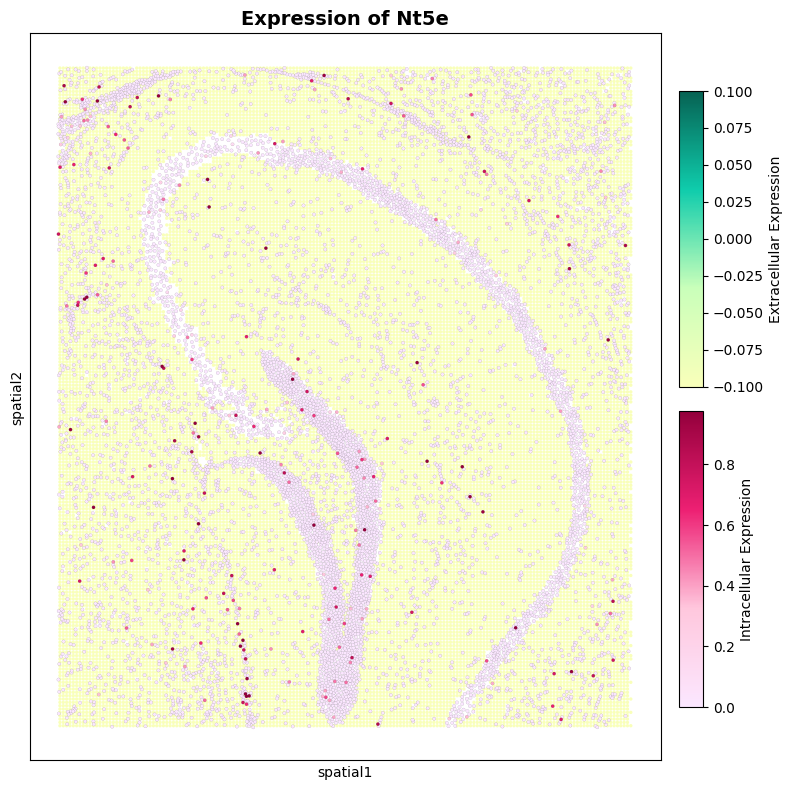

In [142]:
g2 = "Nt5e"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

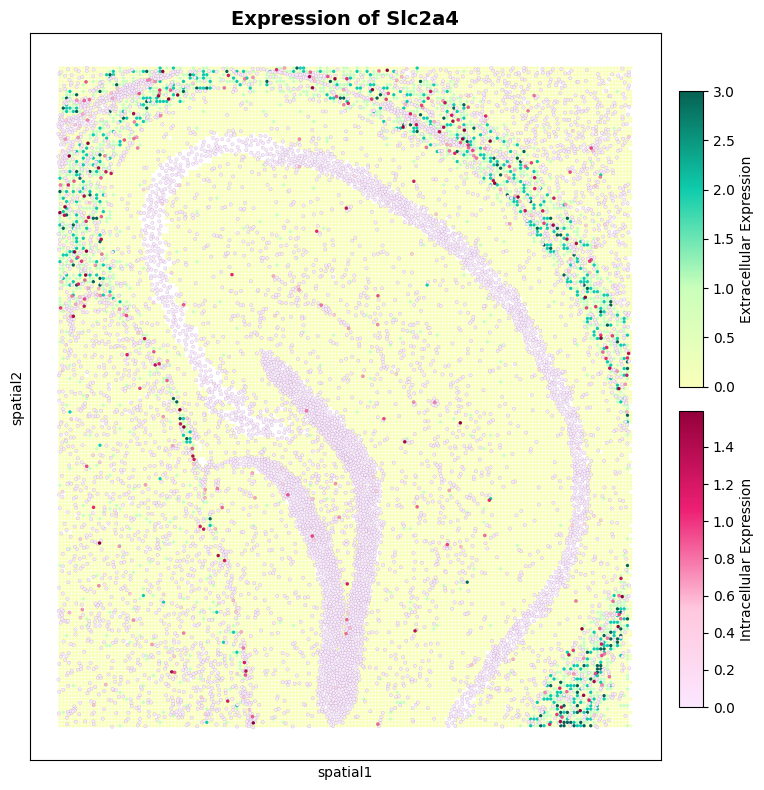

In [136]:
g2 = "Slc2a4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

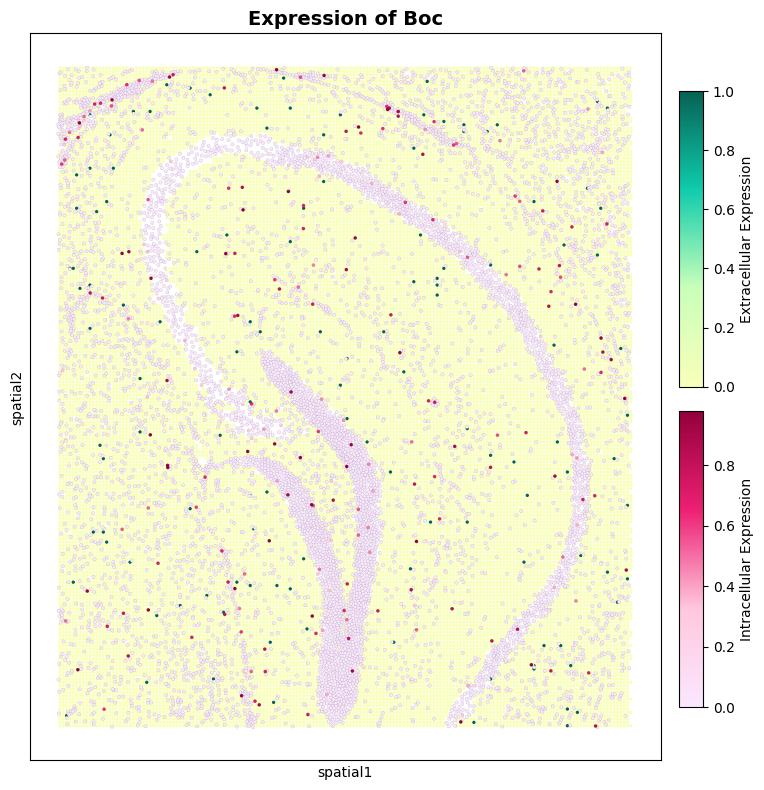

In [131]:
g2 = "Boc"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

import seaborn as sns
import pandas as pd

variable = "logfoldratio_over_noise"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].mean().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)

Text(0.5, 1.0, 'extracellular_proportion')

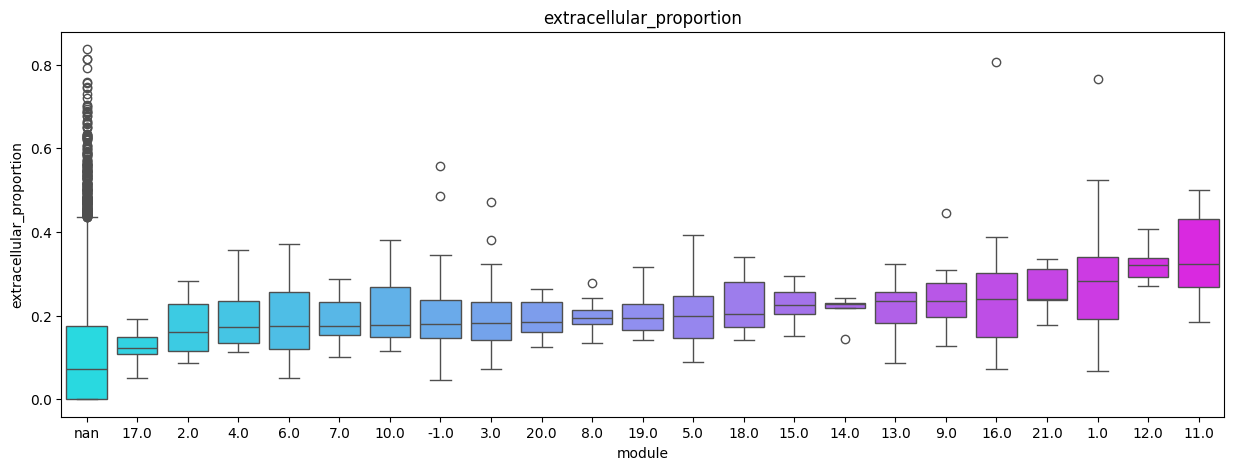

In [134]:
import seaborn as sns
import pandas as pd

variable = "extracellular_proportion"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)

plt.title(variable)